# Single Intervention Demo
## Tropical Reforestation at 0°N, SSP2-4.5

This notebook demonstrates the full pipeline:
1. Compute NEE timeseries from the carbon module
2. Compute albedo forcing
3. Run FaIR baseline and perturbed
4. Plot ΔT(t) and identify break-even year t*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from nbs.carbon_module import compute_nee_timeseries
from nbs.albedo_module import compute_albedo_forcing_timeseries
from nbs.fair_module import run_fair_baseline, run_fair_perturbed, compute_delta_t, find_breakeven_year
from nbs.parameters import T_START, T_END

years = np.arange(T_START, T_END)

## 1. Carbon Module: NEE Timeseries

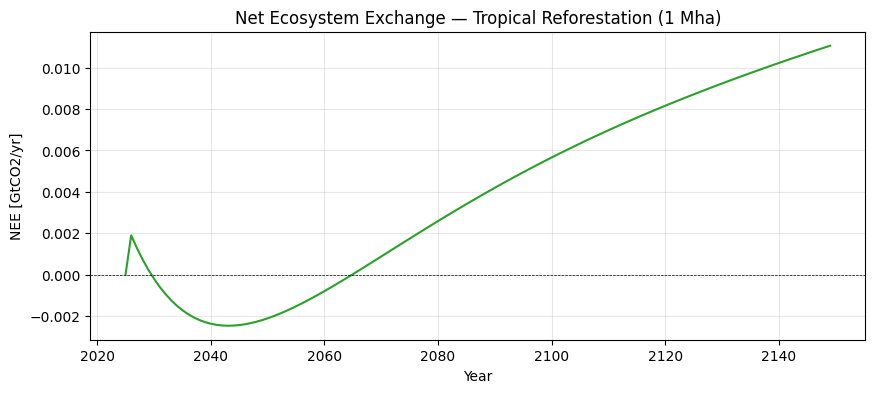

Cumulative removal by 2150: 0.48 GtCO2


In [3]:
nee = compute_nee_timeseries("boreal_afforestation", lat=0, area_mha=1.0)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(years, nee, color="#2ca02c")
ax.axhline(0, color="black", linewidth=0.5, linestyle="--")
ax.set_xlabel("Year")
ax.set_ylabel("NEE [GtCO2/yr]")
ax.set_title("Net Ecosystem Exchange — Tropical Reforestation (1 Mha)")
ax.grid(True, alpha=0.3)
plt.show()

print(f"Cumulative removal by 2150: {np.sum(nee):.2f} GtCO2")

## 2. Albedo Forcing

In [6]:
albedo_rf = compute_albedo_forcing_timeseries("tropical_reforestation", lat=0)
print(f"Steady-state albedo forcing: {albedo_rf[-1]:.3f} W/m2 (negative = slight cooling)")

Steady-state albedo forcing: -0.300 W/m2 (negative = slight cooling)


## 3. FaIR: Baseline vs Perturbed

In [4]:
print("Running FaIR baseline...")
T_base = run_fair_baseline("ssp245")

print("Running FaIR perturbed...")
T_pert = run_fair_perturbed(nee, albedo_rf, "ssp245")

delta_t = compute_delta_t(T_pert, T_base)
t_star = find_breakeven_year(delta_t)
print(f"\nBreak-even year: {t_star}")

Running FaIR baseline...


Running 1 projections in parallel:   0%|          | 0/400 [00:00<?, ?timesteps/s]

Running FaIR perturbed...


Running 1 projections in parallel:   0%|          | 0/400 [00:00<?, ?timesteps/s]


Break-even year: 2025.0


## 4. Temperature Impact: ΔT(t)

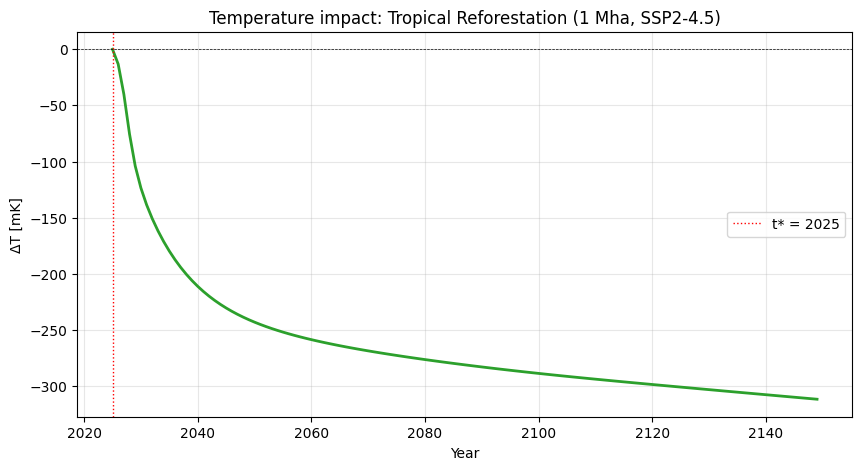

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(years[:len(delta_t)], delta_t * 1000, color="#2ca02c", linewidth=2)
ax.axhline(0, color="black", linewidth=0.5, linestyle="--")
if t_star != np.inf:
    ax.axvline(t_star, color="red", linewidth=1, linestyle=":", label=f"t* = {t_star:.0f}")
    ax.legend()
ax.set_xlabel("Year")
ax.set_ylabel("ΔT [mK]")
ax.set_title("Temperature impact: Tropical Reforestation (1 Mha, SSP2-4.5)")
ax.grid(True, alpha=0.3)
plt.show()

## 5. Compare All Four Interventions

Running 1 projections in parallel:   0%|          | 0/400 [00:00<?, ?timesteps/s]

Running 1 projections in parallel:   0%|          | 0/400 [00:00<?, ?timesteps/s]

Running 1 projections in parallel:   0%|          | 0/400 [00:00<?, ?timesteps/s]

Running 1 projections in parallel:   0%|          | 0/400 [00:00<?, ?timesteps/s]

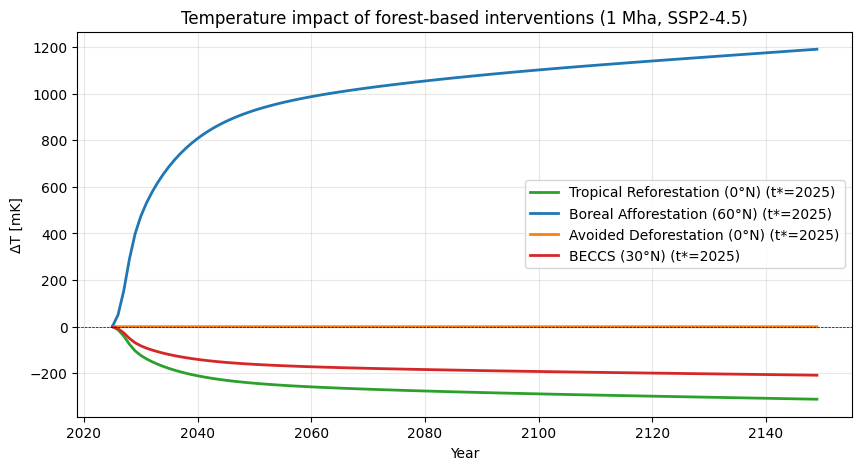

In [6]:
interventions = {
    "tropical_reforestation": (0, "#2ca02c", "Tropical Reforestation (0°N)"),
    "boreal_afforestation": (60, "#1f77b4", "Boreal Afforestation (60°N)"),
    "avoided_deforestation": (0, "#ff7f0e", "Avoided Deforestation (0°N)"),
    "beccs": (30, "#d62728", "BECCS (30°N)"),
}

fig, ax = plt.subplots(figsize=(10, 5))

for intervention, (lat, color, label) in interventions.items():
    nee_i = compute_nee_timeseries(intervention, lat=lat, area_mha=1.0)
    albedo_i = compute_albedo_forcing_timeseries(intervention, lat=lat)
    T_pert_i = run_fair_perturbed(nee_i, albedo_i, "ssp245")
    dt_i = compute_delta_t(T_pert_i, T_base)
    t_star_i = find_breakeven_year(dt_i)

    ax.plot(years[:len(dt_i)], dt_i * 1000, color=color, linewidth=2, label=f"{label} (t*={t_star_i:.0f})")

ax.axhline(0, color="black", linewidth=0.5, linestyle="--")
ax.set_xlabel("Year")
ax.set_ylabel("ΔT [mK]")
ax.set_title("Temperature impact of forest-based interventions (1 Mha, SSP2-4.5)")
ax.legend(loc="best")
ax.grid(True, alpha=0.3)
plt.show()